# Práctica calificada 3 · Solucionario
**Programación con restricciones y minería de patrones | Python · Google Colab**

En Colab, selecciona **Entorno de ejecución → Ejecutar todas**. Basta con CPU. Los datos están incluidos y las salidas guardadas permiten revisar los resultados antes de ejecutar el código.

1. **Final de videojuegos** · Reconstruir la tabla y demostrar unicidad.
2. **Navegación web** · Contar sesiones que contienen una subsecuencia y limitar la separación entre eventos.
3. **Segmentación de jugadores** · Minimizar distancias entre pares y medir el efecto de las restricciones.
4. **Cafetería** · Contrastar FP-Growth con CP-SAT e interpretar una regla de asociación.

### Preparación
La primera celda instala las dos bibliotecas de modelamiento si hace falta. En los ejercicios de enumeración se usa un solo trabajador y se espera al final de la búsqueda. Todas las verificaciones con `assert` deben completarse sin error.

In [1]:
import sys
import subprocess
from importlib.metadata import PackageNotFoundError, version

requeridos = {"ortools": "9.14.6206", "mlxtend": "0.23.4"}
pendientes = []
for paquete, esperado in requeridos.items():
    try:
        instalado = version(paquete)
    except PackageNotFoundError:
        instalado = None
    if instalado != esperado:
        pendientes.append(f"{paquete}=={esperado}")
if pendientes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pendientes])

from itertools import combinations, product
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mlxtend.frequent_patterns import fpgrowth
from ortools.sat.python import cp_model

print("OR-Tools", version("ortools"), " | mlxtend", version("mlxtend"))

OR-Tools 9.14.6206  | mlxtend 0.23.4


Esta función común guarda los valores de las variables solicitadas cada vez que CP-SAT encuentra una solución. Devuelve también el estado final. En un problema de satisfacción, con enumeración exhaustiva, `OPTIMAL` indica que se agotó la búsqueda con soluciones e `INFEASIBLE` que ninguna satisface las restricciones.

In [2]:
class Recolector(cp_model.CpSolverSolutionCallback):
    def __init__(self, variables):
        super().__init__()
        self.variables = variables
        self.filas = []

    def on_solution_callback(self):
        self.filas.append(tuple(self.value(v) for v in self.variables))


def enumerar(modelo, variables):
    solver = cp_model.CpSolver()
    solver.parameters.enumerate_all_solutions = True
    solver.parameters.num_search_workers = 1
    registro = Recolector(variables)
    estado = solver.solve(modelo, registro)
    assert estado in (cp_model.OPTIMAL, cp_model.INFEASIBLE), solver.status_name(estado)
    return solver.status_name(estado), registro.filas

## 1. El misterio de la final de videojuegos
### a. Posiciones y relaciones
Para cada valor de cada categoría se crea una variable entera de **1 a 5**. Por ejemplo, $p_{Ana}=3$ significa que Ana ocupa la tercera estación. Cada categoría es una permutación de las cinco posiciones. Dos atributos que coinciden en una estación tienen el mismo valor.

En cada pista de vecindad, un booleano elige la dirección. Si vale 1, el primer elemento queda inmediatamente a la izquierda del segundo. Si vale 0, se impone el orden inverso.

In [3]:
categorias = {
    "Jugador": ["Ana", "Bruno", "Clara", "Diego", "Elisa"],
    "Personaje": ["Rayo", "Sombra", "Titán", "Ninja", "Mago"],
    "Equipo": ["Lobos", "Dragones", "Cóndores", "Pumas", "Zorros"],
    "Premio": ["Medalla", "Mando", "Audífonos", "Teclado", "Mouse"],
    "Color": ["Rojo", "Azul", "Amarillo", "Verde", "Morado"],
}

def izquierda(modelo, a, b):
    modelo.add(a + 1 == b)

def vecinos(modelo, a, b):
    primero_a = modelo.new_bool_var(f"{a.name}_antes_de_{b.name}")
    modelo.add(a + 1 == b).only_enforce_if(primero_a)
    modelo.add(b + 1 == a).only_enforce_if(primero_a.Not())

torneo = cp_model.CpModel()
pos = {}
for elementos in categorias.values():
    for nombre in elementos:
        pos[nombre] = torneo.new_int_var(1, 5, nombre)
    torneo.add_all_different([pos[n] for n in elementos])

fijas = {"Bruno": 1, "Amarillo": 3, "Morado": 5}  # Pistas 1–3
coinciden = [("Dragones", "Rojo"), ("Titán", "Audífonos"), ("Teclado", "Verde"),
             ("Lobos", "Mago"), ("Diego", "Azul"), ("Elisa", "Ninja"), ("Sombra", "Mouse")]
adyacentes = [("Ana", "Cóndores"), ("Elisa", "Mando")]
a_la_izquierda = [("Medalla", "Zorros"), ("Bruno", "Audífonos"), ("Rayo", "Dragones")]

for nombre, estacion in fijas.items():
    torneo.add(pos[nombre] == estacion)
for a, b in coinciden:  # Pistas 4–10
    torneo.add(pos[a] == pos[b])
for a, b in adyacentes:  # Pistas 11–12
    vecinos(torneo, pos[a], pos[b])
for a, b in a_la_izquierda:  # Pistas 13–15
    izquierda(torneo, pos[a], pos[b])

### b–c. Tabla, respuestas y unicidad
Se enumeran las asignaciones completas y se validan las 15 pistas sobre los números devueltos. La tabla invierte la representación del modelo para poder leerla de izquierda a derecha por estación.

In [4]:
estado, filas = enumerar(torneo, list(pos.values()))
asignaciones = set(filas)
print(f"Estado: {estado} | Asignaciones completas distintas: {len(asignaciones)}")
assert len(asignaciones) == 1
p = dict(zip(pos, filas[0]))
for nombres in categorias.values():
    assert {p[n] for n in nombres} == set(range(1, 6))
assert all(p[n] == k for n, k in fijas.items())
assert all(p[a] == p[b] for a, b in coinciden)
assert all(abs(p[a] - p[b]) == 1 for a, b in adyacentes)
assert all(p[b] - p[a] == 1 for a, b in a_la_izquierda)

estaciones = pd.DataFrame({c: sorted(nombres, key=p.get) for c, nombres in categorias.items()},
                          index=pd.Index(range(1, 6), name="Estación"))
display(estaciones)
print("Teclado:", estaciones.loc[p["Teclado"], "Jugador"])
print("Personaje de Zorros:", estaciones.loc[p["Zorros"], "Personaje"])
print("Jugador central:", estaciones.loc[3, "Jugador"])
print("Equipos en los extremos:", estaciones.loc[1, "Equipo"], "y", estaciones.loc[5, "Equipo"])

Estado: OPTIMAL | Asignaciones completas distintas: 1


,Jugador,Personaje,Equipo,Premio,Color
Estación,,,,,
1,Bruno,Mago,Lobos,Teclado,Verde
2,Diego,Titán,Cóndores,Audífonos,Azul
3,Ana,Rayo,Pumas,Mando,Amarillo
4,Elisa,Ninja,Dragones,Medalla,Rojo
5,Clara,Sombra,Zorros,Mouse,Morado


Teclado: Bruno
Personaje de Zorros: Sombra
Jugador central: Ana
Equipos en los extremos: Lobos y Zorros


### d. Ana en un extremo
El modelo original tiene una única asignación y en ella Ana ocupa la estación 3. Restringir su posición a 1 o 5 elimina esa única posibilidad.

In [5]:
extremos = torneo.clone()
ana_copia = extremos.get_int_var_from_proto_index(pos["Ana"].index)
extremos.add_allowed_assignments([ana_copia], [(1,), (5,)])
solver_extremos = cp_model.CpSolver()
estado_extremos = solver_extremos.solve(extremos)
print("Modelo con Ana en un extremo:", solver_extremos.status_name(estado_extremos))
assert estado_extremos == cp_model.INFEASIBLE

Modelo con Ana en un extremo: INFEASIBLE


## 2. ¿Cómo navegan los usuarios para comprar entradas?
### a. Sesiones y cálculo manual
El denominador son las **12 sesiones**, incluidas S06 y S10, que terminan antes del pago. Se requieren al menos $\lceil 0.50\times 12\rceil=6$ sesiones.

| Patrón | Sesiones que lo contienen en orden | Frecuencia | Soporte |
|---|---|---:|---:|
| búsqueda → pago | S01, S02, S03, S04, S05, S08, S09, S11, S12 | 9 | 9/12 = 75 % |
| búsqueda → evento → pago | S01, S02, S03, S05, S08, S11, S12 | 7 | 7/12 ≈ 58.33 % |

S03 cubre el segundo patrón porque después de «búsqueda» hay una segunda visita a «evento». S08 admite varias maneras de elegir posiciones y aporta una sola sesión.

In [6]:
paginas = ["inicio", "búsqueda", "evento", "zona", "carrito", "pago"]
por_letra = dict(zip("ibezcp", paginas))
rutas = ["ibezcp", "ibecp", "iebezp", "ibzcp", "ibep", "ibezc",
         "iezcp", "ibebep", "ibcp", "ibez", "ibezp", "ibiecp"]
sesiones = {f"S{i:02}": tuple(por_letra[c] for c in ruta)
            for i, ruta in enumerate(rutas, 1)}
display(pd.Series({s: " → ".join(r) for s, r in sesiones.items()}, name="Ruta").to_frame())

,Ruta
S01,inicio → búsqueda → evento → zona → carrito → ...
S02,inicio → búsqueda → evento → carrito → pago
S03,inicio → evento → búsqueda → evento → zona → pago
S04,inicio → búsqueda → zona → carrito → pago
S05,inicio → búsqueda → evento → pago
S06,inicio → búsqueda → evento → zona → carrito
S07,inicio → evento → zona → carrito → pago
S08,inicio → búsqueda → evento → búsqueda → evento...
S09,inicio → búsqueda → carrito → pago
S10,inicio → búsqueda → evento → zona


### b–c. Modelo de cobertura exacta y separación máxima
Se resuelve un modelo por longitud $L\in\{2,3,4\}$. Cada posición tiene una variable entera con dominio de 0 a 5, un código por página. Se fijan la primera y última página a búsqueda y pago. Las posiciones internas admiten repeticiones.

Para cada sesión se precalculan sus subsecuencias de longitud $L$. Una tabla permitida vincula **cada patrón candidato** con el único valor correcto de su booleano de cobertura, 0 o 1. CP-SAT exige que la suma de esos booleanos alcance 6. Con `max_gap=1`, dos índices sucesivos elegidos pueden diferir como máximo en 2.

In [7]:
codigo = {pagina: i for i, pagina in enumerate(paginas)}
min_sesiones = ceil(0.50 * len(sesiones))

def subsecuencias(ruta, longitud, max_gap):
    presentes = set()
    for indices in combinations(range(len(ruta)), longitud):
        if max_gap is None or all(b - a - 1 <= max_gap for a, b in zip(indices, indices[1:])):
            presentes.add(tuple(codigo[ruta[i]] for i in indices))
    return presentes

def buscar_recorridos(max_gap):
    encontrados = {}
    for longitud in (2, 3, 4):
        modelo = cp_model.CpModel()
        eventos = [modelo.new_int_var(0, len(paginas)-1, f"evento_{i}") for i in range(longitud)]
        modelo.add(eventos[0] == codigo["búsqueda"])
        modelo.add(eventos[-1] == codigo["pago"])
        candidatos = [(codigo["búsqueda"], *medio, codigo["pago"])
                      for medio in product(range(len(paginas)), repeat=longitud-2)]
        cobertura = []
        for sesion, ruta in sesiones.items():
            cubre = modelo.new_bool_var(sesion)
            presentes = subsecuencias(ruta, longitud, max_gap)
            tabla = [(*patron, int(patron in presentes)) for patron in candidatos]
            modelo.add_allowed_assignments([*eventos, cubre], tabla)
            cobertura.append(cubre)
        modelo.add(sum(cobertura) >= min_sesiones)
        estado, filas = enumerar(modelo, [*eventos, *cobertura])
        print(f"L = {longitud} | {estado} | {len(filas)} patrones")
        for fila in filas:
            patron = tuple(paginas[k] for k in fila[:longitud])
            encontrados[patron] = tuple(s for s, bit in zip(sesiones, fila[longitud:]) if bit)
    return encontrados

def tabla_recorridos(resultados):
    return pd.DataFrame([{"Patrón": " → ".join(p), "Longitud": len(p),
                          "Frecuencia": len(ids), "Soporte": f"{len(ids)/len(sesiones):.2%}",
                          "Sesiones": ", ".join(ids)} for p, ids in sorted(resultados.items(), key=lambda r: len(r[0]))])

print("Sin límite de separación")
libres = buscar_recorridos(None)
display(tabla_recorridos(libres))
print("Con un máximo de un evento omitido por salto")
limitados = buscar_recorridos(1)
display(tabla_recorridos(limitados))

Sin límite de separación
L = 2 | OPTIMAL | 1 patrones
L = 3 | OPTIMAL | 1 patrones
L = 4 | INFEASIBLE | 0 patrones


,Patrón,Longitud,Frecuencia,Soporte,Sesiones
0,búsqueda → pago,2,9,75.00%,"S01, S02, S03, S04, S05, S08, S09, S11, S12"
1,búsqueda → evento → pago,3,7,58.33%,"S01, S02, S03, S05, S08, S11, S12"


Con un máximo de un evento omitido por salto
L = 2 | INFEASIBLE | 0 patrones
L = 3 | OPTIMAL | 1 patrones
L = 4 | INFEASIBLE | 0 patrones


,Patrón,Longitud,Frecuencia,Soporte,Sesiones
0,búsqueda → evento → pago,3,6,50.00%,"S02, S03, S05, S08, S11, S12"


In [8]:
# Comprobación independiente a partir de las sesiones identificadas a mano.
bp = ("búsqueda", "pago")
bep = ("búsqueda", "evento", "pago")
assert libres == {bp: tuple("S01 S02 S03 S04 S05 S08 S09 S11 S12".split()),
                  bep: tuple("S01 S02 S03 S05 S08 S11 S12".split())}
assert limitados == {bep: tuple("S02 S03 S05 S08 S11 S12".split())}
# El patrón corto cae bajo el mínimo. Recuperamos incluso sus sesiones descartadas por el filtro.
corto = tuple(codigo[p] for p in bp)
quedan = [s for s, r in sesiones.items() if corto in subsecuencias(r, 2, 1)]
assert quedan == ["S05", "S08", "S09"]
print("búsqueda → pago con max_gap = 1:", ", ".join(quedan), f"({len(quedan)}/12)")

búsqueda → pago con max_gap = 1: S05, S08, S09 (3/12)


### d. Interpretación
**Búsqueda → pago** pasa de 9 a 3 sesiones (25 %) y pierde el soporte mínimo. **Búsqueda → evento → pago** pasa de 7 a 6 (50 %) y permanece. En S11, por ejemplo, entre búsqueda y pago hay dos páginas, evento y zona. Al incluir evento en el patrón, el primer salto es directo y el segundo omite únicamente zona.

La unidad de análisis es la sesión. Contar cada aparición daría más peso a quienes retroceden y repiten páginas. El soporte describe cuántas sesiones siguieron el recorrido. Para atribuirle un efecto sobre la compra habría que comparar alternativas, por ejemplo asignando aleatoriamente a los usuarios a distintos flujos y midiendo la tasa de pago.

## 3. Segmentación de jugadores con restricciones
### a. Exploración y estandarización
En el gráfico se distinguen tres franjas de horas semanales (2–4, 9–12 y 20–23) con un aumento paralelo del número de partidas. Para que una variable con mayor dispersión numérica no domine la distancia, se centra cada columna en su media y se divide por su desviación estándar **poblacional** ($ddof=0$). Así, una diferencia de una desviación estándar tiene el mismo peso en ambos ejes.

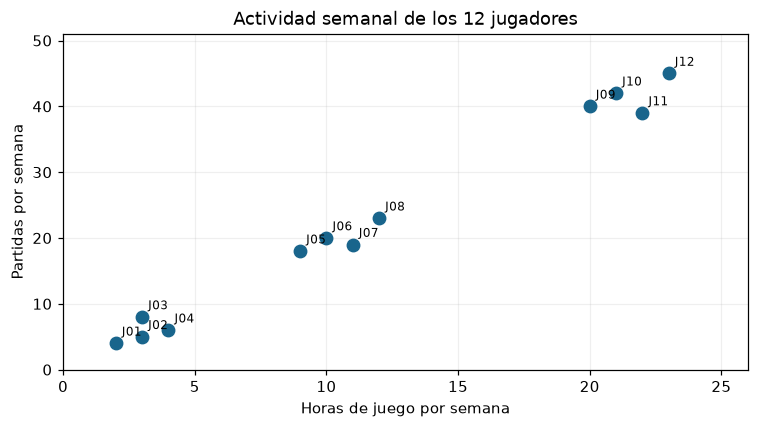

In [9]:
actividad = pd.DataFrame(
    [(2, 4), (3, 5), (3, 8), (4, 6), (9, 18), (10, 20), (11, 19), (12, 23),
     (20, 40), (21, 42), (22, 39), (23, 45)],
    columns=["Horas", "Partidas"], index=[f"J{i:02}" for i in range(1, 13)])
jugadores = list(actividad.index)
z = (actividad - actividad.mean()) / actividad.std(ddof=0)
assert np.allclose(z.mean(), 0) and np.allclose(z.std(ddof=0), 1)
pares = list(combinations(jugadores, 2))
costos = {(i, j): round(1000 * float(((z.loc[i] - z.loc[j])**2).sum())) for i, j in pares}

def graficar_grupos(ax, grupos, titulo):
    colores = ["#19658c", "#c05c12", "#5a418b"]
    marcas = ["o", "s", "^"]
    for k, grupo in enumerate(grupos):
        datos = actividad.loc[list(grupo)]
        ax.scatter(datos.Horas, datos.Partidas, color=colores[k], marker=marcas[k],
                   s=65, label=f"Grupo {k+1}", zorder=3)
    for nombre, fila in actividad.iterrows():
        ax.annotate(nombre, (fila.Horas, fila.Partidas), xytext=(4, 5),
                    textcoords="offset points", fontsize=8)
    ax.set(xlabel="Horas de juego por semana", ylabel="Partidas por semana",
           title=titulo, xlim=(0, 26), ylim=(0, 51))
    ax.grid(alpha=0.2)
    if len(grupos) > 1:
        ax.legend(loc="upper left", fontsize=8)

fig, ax = plt.subplots(figsize=(7, 4))
graficar_grupos(ax, [jugadores], "Actividad semanal de los 12 jugadores")
plt.tight_layout()
plt.show()

### b–c. Modelo base y modelo con condiciones adicionales
* $g_i\in\{0,1,2\}$ indica el grupo del jugador $i$.
* $x_{ik}\in\{0,1\}$ equivale a $g_i=k$. Cada jugador pertenece exactamente a un grupo y $3\leq\sum_i x_{ik}\leq5$ para cada grupo.
* $y_{ij}\in\{0,1\}$ equivale a $g_i=g_j$. Se minimiza $\sum_{i<j}w_{ij}y_{ij}$ con $w_{ij}=\operatorname{round}(1000\lVert z_i-z_j\rVert^2)$. Se redondea cada costo antes de la suma y cada pareja se cuenta una sola vez.

Los dos sentidos de cada equivalencia se programan con restricciones condicionadas. El modelo adicional incorpora dos igualdades (hogares) y dos desigualdades (campaña) sobre las variables de grupo.

In [10]:
mismo_hogar = [("J01", "J02"), ("J05", "J06")]
separados = [("J01", "J03"), ("J09", "J10")]

def modelo_grupos(con_vinculos):
    m = cp_model.CpModel()
    g = {i: m.new_int_var(0, 2, i) for i in jugadores}
    pertenece = {}
    for i in jugadores:
        for k in range(3):
            x = m.new_bool_var(f"{i}_grupo_{k}")
            m.add(g[i] == k).only_enforce_if(x)
            m.add(g[i] != k).only_enforce_if(x.Not())
            pertenece[i, k] = x
        m.add_exactly_one(pertenece[i, k] for k in range(3))
    for k in range(3):
        m.add_linear_constraint(sum(pertenece[i, k] for i in jugadores), 3, 5)
    juntos = {}
    for i, j in pares:
        y = m.new_bool_var(f"juntos_{i}_{j}")
        m.add(g[i] == g[j]).only_enforce_if(y)
        m.add(g[i] != g[j]).only_enforce_if(y.Not())
        juntos[i, j] = y
    if con_vinculos:
        for i, j in mismo_hogar:
            m.add(g[i] == g[j])
        for i, j in separados:
            m.add(g[i] != g[j])
    m.minimize(sum(costos[par] * juntos[par] for par in pares))
    return m, g

def resolver_grupos(m, g, con_vinculos):
    solver = cp_model.CpSolver()
    estado = solver.solve(m)
    print("Estado:", solver.status_name(estado))
    assert estado in (cp_model.FEASIBLE, cp_model.OPTIMAL)
    asignado = {i: solver.value(g[i]) for i in jugadores}
    # Orden canónico por integrantes: se pueden comparar particiones con etiquetas distintas.
    grupos = sorted(tuple(i for i in jugadores if asignado[i] == k) for k in range(3))
    assert sorted(i for grupo in grupos for i in grupo) == jugadores
    assert all(3 <= len(grupo) <= 5 for grupo in grupos)
    if con_vinculos:
        assert all(asignado[i] == asignado[j] for i, j in mismo_hogar)
        assert all(asignado[i] != asignado[j] for i, j in separados)
    valor = sum(costos[i, j] for i, j in pares if asignado[i] == asignado[j])
    assert valor == round(solver.objective_value)
    print(f"Costo por pares: {valor} | Mejor cota: {solver.best_objective_bound:.0f}")
    display(pd.DataFrame([{"Grupo": k, "Integrantes": ", ".join(grupo), "Tamaño": len(grupo)}
                          for k, grupo in enumerate(grupos, 1)]).set_index("Grupo"))
    return grupos, valor, estado

base, g_base = modelo_grupos(False)
adicional, g_adicional = modelo_grupos(True)
print("Modelo base")
grupos_base, costo_base, estado_base = resolver_grupos(base, g_base, False)
print("Modelo con vínculos")
grupos_ad, costo_ad, estado_ad = resolver_grupos(adicional, g_adicional, True)
assert estado_base == estado_ad == cp_model.OPTIMAL
assert (costo_base, costo_ad) == (1615, 29840)

Modelo base
Estado: OPTIMAL
Costo por pares: 1615 | Mejor cota: 1615


,Integrantes,Tamaño
Grupo,,
1,"J01, J02, J03, J04",4
2,"J05, J06, J07, J08",4
3,"J09, J10, J11, J12",4


Modelo con vínculos
Estado: OPTIMAL
Costo por pares: 29840 | Mejor cota: 29840


,Integrantes,Tamaño
Grupo,,
1,"J01, J02, J04, J05, J06",5
2,"J03, J07, J08, J09",4
3,"J10, J11, J12",3


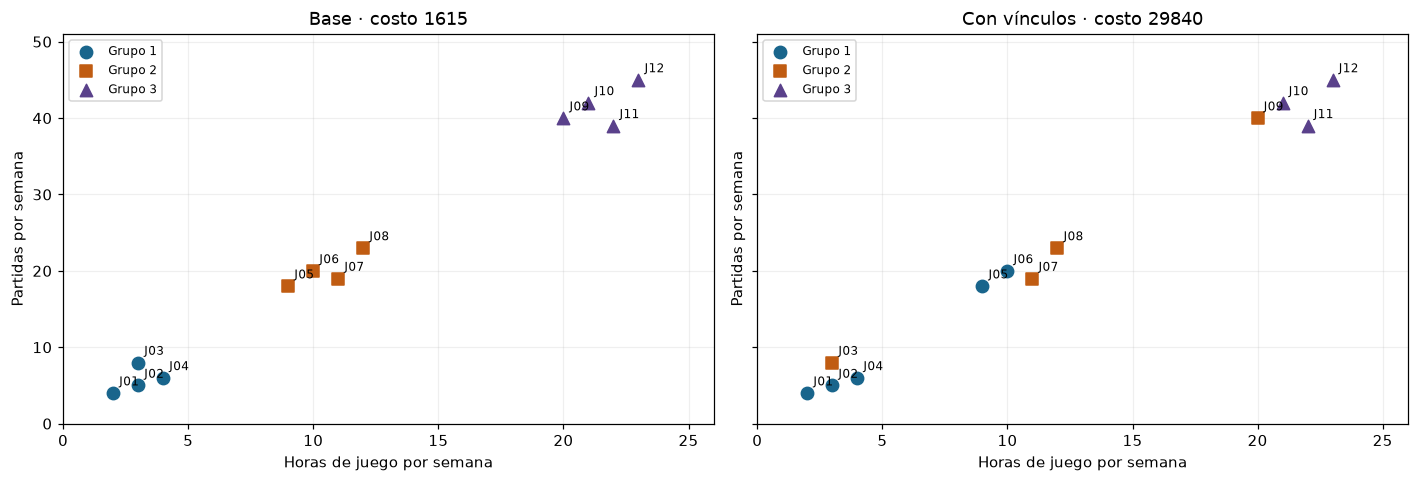

Pares que siguen juntos: 8
Pares que se separan: 10
Nuevos pares dentro del mismo grupo: 11
Aumento del costo: 28225 unidades


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
graficar_grupos(axes[0], grupos_base, f"Base · costo {costo_base}")
graficar_grupos(axes[1], grupos_ad, f"Con vínculos · costo {costo_ad}")
plt.tight_layout()
plt.show()

def pares_internos(grupos):
    return {par for grupo in grupos for par in combinations(grupo, 2)}

antes, despues = pares_internos(grupos_base), pares_internos(grupos_ad)
print(f"Pares que siguen juntos: {len(antes & despues)}")
print(f"Pares que se separan: {len(antes - despues)}")
print(f"Nuevos pares dentro del mismo grupo: {len(despues - antes)}")
print(f"Aumento del costo: {costo_ad - costo_base} unidades")

El óptimo base agrupa los tres bloques de cuatro jugadores que se observan en el primer gráfico. Las separaciones J01–J03 y J09–J10 obligan a romper dos de esos bloques. La mejor partición permitida cuesta **29 840**, frente a **1 615** del modelo base. El aumento de **28 225** cuantifica el costo de respetar esas decisiones en la escala entera del objetivo. Cambiar los números de los grupos conserva los pares internos y el costo.

Un estado `FEASIBLE` acredita que la partición satisface las condiciones. En estas dos ejecuciones se obtiene `OPTIMAL`: el solver también demuestra que ningún costo menor es alcanzable.

### d. Diagnóstico de inviabilidad
Si J01 y J02 están juntos y además J02 y J03 deben estar juntos, la igualdad obliga a reunir a J01 y J03. La campaña exige separarlos. Una corrección concreta es retirar el nuevo vínculo J02–J03 y conservar las condiciones originales. El modelo adicional ya resuelto demuestra que esa corrección recupera la factibilidad.

In [12]:
contradiccion = adicional.clone()
g2 = contradiccion.get_int_var_from_proto_index(g_adicional["J02"].index)
g3 = contradiccion.get_int_var_from_proto_index(g_adicional["J03"].index)
contradiccion.add(g2 == g3)
solver_conflicto = cp_model.CpSolver()
estado_conflicto = solver_conflicto.solve(contradiccion)
print("Con el nuevo vínculo J02–J03:", solver_conflicto.status_name(estado_conflicto))
assert estado_conflicto == cp_model.INFEASIBLE

Con el nuevo vínculo J02–J03: INFEASIBLE


## 4. Combos para una cafetería universitaria
### a. Matriz binaria y cálculo manual
Las filas representan compras y las columnas productos. Un 1 indica presencia. T01 y T14 tienen igual contenido y cuentan por separado, al igual que T05 y T16.

| Conjunto | Compras que lo contienen (número de T) | Frecuencia | Soporte |
|---|---|---:|---:|
| Sándwich | 01, 02, 03, 05, 06, 07, 10, 11, 13, 14, 15, 16, 18, 20 | 14 | 70 % |
| Café | 01, 02, 04, 05, 07, 09, 11, 12, 14, 16, 17, 18 | 12 | 60 % |
| Sándwich y Café | 01, 02, 05, 07, 11, 14, 16, 18 | 8 | 40 % |

El 20 % de 20 compras exige una frecuencia absoluta mínima de **4**.

In [13]:
producto = {"S": "Sándwich", "C": "Café", "E": "Empanada", "J": "Jugo",
            "A": "Agua", "G": "Galleta", "B": "Brownie"}
tickets = ["SCE", "SC", "SE", "CE", "SCJ", "SJ", "SCEJ", "AG", "AGC", "AS",
           "SCB", "CB", "SB", "SCE", "AGS", "SCJ", "CEB", "SCBJ", "AGB", "SEJ"]
compras = {f"T{i:02}": {producto[c] for c in ticket} for i, ticket in enumerate(tickets, 1)}
productos = list(producto.values())
bebidas = {"Café", "Jugo", "Agua"}
n_compras = len(compras)
matriz = pd.DataFrame([[p in t for p in productos] for t in compras.values()],
                      index=pd.Index(compras, name="Compra"), columns=productos)
display(matriz.astype(int))

def frecuencia(conjunto):
    return sum(conjunto <= compra for compra in compras.values())

assert [frecuencia(s) for s in [{"Sándwich"}, {"Café"}, {"Sándwich", "Café"}]] == [14, 12, 8]
print("Frecuencia mínima:", ceil(0.20 * n_compras))

,Sándwich,Café,Empanada,Jugo,Agua,Galleta,Brownie
Compra,,,,,,,
T01,1,1,1,0,0,0,0
T02,1,1,0,0,0,0,0
T03,1,0,1,0,0,0,0
T04,0,1,1,0,0,0,0
T05,1,1,0,1,0,0,0
T06,1,0,0,1,0,0,0
T07,1,1,1,1,0,0,0
T08,0,0,0,0,1,1,0
T09,0,1,0,0,1,1,0


Frecuencia mínima: 4


### b. Conjuntos frecuentes con FP-Growth
FP-Growth opera sobre la matriz booleana y devuelve todos los conjuntos frecuentes no vacíos. Recién después se aplican las reglas comerciales: tamaño 2 o 3, presencia de alguna bebida y exclusión del par Café–Jugo. Se conservan las frecuencias absolutas para la comparación.

In [14]:
def es_comercial(conjunto):
    return (2 <= len(conjunto) <= 3 and bool(conjunto & bebidas)
            and not {"Café", "Jugo"} <= conjunto)

def frecuentes_fp(umbral):
    salida = fpgrowth(matriz, min_support=umbral, use_colnames=True)
    return {fila.itemsets: round(fila.support * n_compras) for fila in salida.itertuples()}

def tabla_conjuntos(resultados):
    ordenados = sorted(resultados.items(), key=lambda par: (len(par[0]), -par[1], sorted(par[0])))
    return pd.DataFrame([{"Productos": " + ".join(sorted(s)), "Frecuencia": f,
                          "Soporte": f"{f/n_compras:.0%}"} for s, f in ordenados])

frecuentes20 = frecuentes_fp(0.20)
fp20 = {s: f for s, f in frecuentes20.items() if es_comercial(s)}
print(f"Conjuntos frecuentes no vacíos: {len(frecuentes20)}")
display(tabla_conjuntos(frecuentes20))
print(f"Candidatos tras aplicar las condiciones comerciales: {len(fp20)}")

Conjuntos frecuentes no vacíos: 15


,Productos,Frecuencia,Soporte
0,Sándwich,14,70%
1,Café,12,60%
2,Empanada,7,35%
3,Brownie,6,30%
4,Jugo,6,30%
5,Agua,5,25%
6,Galleta,4,20%
7,Café + Sándwich,8,40%
8,Jugo + Sándwich,6,30%
9,Café + Empanada,5,25%


Candidatos tras aplicar las condiciones comerciales: 5


### c–d. CP-SAT y comparación de candidatos
$x_p$ selecciona el producto $p$. Para cada compra $t$, se cuenta cuántos productos seleccionados faltan en ella: $m_t=\sum_{p\notin t}x_p$. El booleano $c_t$ vale 1 exactamente cuando $m_t=0$. Si vale 0 se exige $m_t\geq1$. La frecuencia entera $F\in[0,20]$ es la suma de las coberturas y debe alcanzar el umbral. Se enumeran candidatos sin función objetivo.

In [15]:
def combos_cp(umbral):
    modelo = cp_model.CpModel()
    seleccion = {p: modelo.new_bool_var(p) for p in productos}
    modelo.add_linear_constraint(sum(seleccion.values()), 2, 3)
    modelo.add(sum(seleccion[p] for p in bebidas) >= 1)
    modelo.add(seleccion["Café"] + seleccion["Jugo"] <= 1)
    cobertura = []
    for ticket, compra in compras.items():
        cubre = modelo.new_bool_var(ticket)
        faltan = sum(seleccion[p] for p in productos if p not in compra)
        modelo.add(faltan == 0).only_enforce_if(cubre)
        modelo.add(faltan >= 1).only_enforce_if(cubre.Not())
        cobertura.append(cubre)
    freq = modelo.new_int_var(0, n_compras, "frecuencia")
    modelo.add(freq == sum(cobertura))
    modelo.add(freq >= ceil(umbral * n_compras))
    estado, filas = enumerar(modelo, [*seleccion.values(), *cobertura, freq])
    print(f"CP-SAT | Umbral {umbral:.0%} | Estado {estado} | {len(filas)} candidatos")
    resultado = {}
    for fila in filas:
        combo = frozenset(p for p, bit in zip(productos, fila) if bit)
        indicadores = fila[len(productos):-1]
        assert indicadores == tuple(int(combo <= compra) for compra in compras.values())
        assert fila[-1] == frecuencia(combo) and es_comercial(combo)
        resultado[combo] = fila[-1]
    return resultado

cp20 = combos_cp(0.20)
assert cp20 == fp20
display(tabla_conjuntos(cp20))
print("FP-Growth y CP-SAT coinciden en todos los conjuntos y frecuencias.")

CP-SAT | Umbral 20% | Estado OPTIMAL | 5 candidatos


,Productos,Frecuencia,Soporte
0,Café + Sándwich,8,40%
1,Jugo + Sándwich,6,30%
2,Café + Empanada,5,25%
3,Agua + Galleta,4,20%
4,Brownie + Café,4,20%


FP-Growth y CP-SAT coinciden en todos los conjuntos y frecuencias.


### e. Regla de asociación · Jugo → Sándwich
El soporte de la regla usa todas las compras como denominador. La confianza usa las compras con jugo. El lift compara esa confianza con la proporción de compras que incluyen sándwich en toda la muestra.

In [16]:
n_jugo = frecuencia({"Jugo"})
n_sandwich = frecuencia({"Sándwich"})
n_ambos = frecuencia({"Jugo", "Sándwich"})
soporte = n_ambos / n_compras
confianza = n_ambos / n_jugo
lift = confianza / (n_sandwich / n_compras)
print(f"Soporte   = {n_ambos}/{n_compras} = {soporte:.0%}")
print(f"Confianza = {n_ambos}/{n_jugo}  = {confianza:.0%}")
print(f"Lift      = {confianza:.2f} / {n_sandwich/n_compras:.2f} = {lift:.4f}")
assert (n_jugo, n_sandwich, n_ambos) == (6, 14, 6)

Soporte   = 6/20 = 30%
Confianza = 6/6  = 100%
Lift      = 1.00 / 0.70 = 1.4286


Seis de las veinte compras incluyen ambos productos (**30 %**). Las seis compras con jugo incluyen sándwich (**100 % de confianza**). La presencia de sándwich entre quienes compran jugo es **1.43 veces** la frecuencia general del sándwich (70 %). La asociación observada se basa en seis compras con jugo. Para evaluar la rentabilidad del combo habría que comparar el margen con y sin la oferta y considerar cuánto descuento recibirían quienes ya compraban ambos productos.

### f. Sensibilidad al 30 %
Con el umbral en 30 % se requieren al menos seis compras. Se vuelven a ejecutar ambos métodos conservando las mismas reglas comerciales.

In [17]:
fp30 = {s: f for s, f in frecuentes_fp(0.30).items() if es_comercial(s)}
cp30 = combos_cp(0.30)
assert cp30 == fp30 == {s: f for s, f in cp20.items() if f >= 6}
display(tabla_conjuntos(cp30))
print("Dejan de calificar:")
display(tabla_conjuntos({s: f for s, f in cp20.items() if s not in cp30}))

CP-SAT | Umbral 30% | Estado OPTIMAL | 2 candidatos


,Productos,Frecuencia,Soporte
0,Café + Sándwich,8,40%
1,Jugo + Sándwich,6,30%


Dejan de calificar:


,Productos,Frecuencia,Soporte
0,Café + Empanada,5,25%
1,Agua + Galleta,4,20%
2,Brownie + Café,4,20%


De los cinco candidatos originales quedan **Café + Sándwich** (8/20) y **Jugo + Sándwich** (6/20). Café + Empanada aparece en cinco compras, y Agua + Galleta y Brownie + Café aparecen en cuatro cada uno. Al subir el umbral se conservan los combos más frecuentes y se reduce la variedad disponible.